# Analyse métier - Étoile Logistique

**Table Druid :** fact_logistics  
**Grain :** Une ligne par commande; en cas de plusieurs vendeurs, un vendeur représentatif est retenu pour les coordonnées et la distance

Ce notebook exécute cinquante visuels depuis la table Druid dénormalisée indiquée ci-dessus. La première cellule détecte une connexion accessible depuis le noyau Python : `http://127.0.0.1:25019/druid/v2/sql` sur l’hôte ou `http://druid-router:8888/druid/v2/sql` dans Docker. Pour imposer une URL, définir `DRUID_SQL_URL_OVERRIDE` ou la variable d’environnement `DRUID_SQL_URL`.

**Limite du modèle :** Le délai et le retard sont des mesures temporelles non additives. Le taux à l’heure doit être calculé uniquement sur les commandes livrées avec dates de livraison et estimation présentes : delivered_on_time vaut 0 également pour une commande non livrée ou non comparable. La distance est calculée vers le vendeur représentatif, pas chaque vendeur d’une commande multi-vendeurs.

**Source du modèle :** [20_build_ebrasil_warehouse.py](https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py), blob GitHub `8b553b3970eb8f3f5804ac0072569cfade518c57`. Le script produit les six tables dénormalisées ; `docker/ebrasil-druid/ingest.py` les ingère sous les mêmes noms, sans rollup. Au démarrage, le notebook contrôle les six tables et les colonnes utilisées par ses graphiques via `INFORMATION_SCHEMA.COLUMNS`, ainsi que la présence de lignes dans sa table. Aucune donnée de démonstration ni dimension séparée n’est utilisée. La compatibilité du schéma est contrôlée ; la provenance des lignes dépend de l’initialisation eBrasil du dépôt.


In [1]:
import os
import socket
import warnings
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# None : sélection automatique depuis le noyau Python, indépendamment du navigateur.
# Pour imposer une adresse, renseigner ceci ou la variable d'environnement DRUID_SQL_URL.
DRUID_SQL_URL_OVERRIDE = None
HOST_SQL_URL = "http://127.0.0.1:25019/druid/v2/sql"
DOCKER_SQL_URL = "http://druid-router:8888/druid/v2/sql"
TABLE = "fact_logistics"
MODEL_TABLES = ["fact_logistics","fact_order","fact_order_item","fact_payment","fact_review","mart_customer_rfm"]
REQUIRED_COLUMNS = ["customer_city","customer_state","customer_zip_code","delivered_date_calendar_date","delivered_on_time","delivered_time_hour","delivery_days","distance_km","estimated_delivery_date_calendar_date","late_days","orders_count","purchase_date_calendar_date","purchase_date_weekday","purchase_date_year","purchase_time_day_part","representative_seller_city","representative_seller_id","representative_seller_state","representative_seller_zip_code","shipped_date_calendar_date","shipped_date_year","status"]
MODEL_SOURCE = "https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py"
MODEL_SOURCE_BLOB_SHA = "8b553b3970eb8f3f5804ac0072569cfade518c57"

def normalize_sql_url(value):
    parsed = urlsplit(value.strip())
    if parsed.scheme not in ("http", "https") or not parsed.hostname:
        raise ValueError("DRUID_SQL_URL doit être une URL HTTP complète, sans syntaxe Markdown.")
    if parsed.username or parsed.password or parsed.query or parsed.fragment:
        raise ValueError("Ne pas inclure d'identifiants, de paramètres ou de fragment dans DRUID_SQL_URL.")
    netloc = parsed.netloc
    if parsed.hostname == "druid-router" and parsed.port == 25019:
        warnings.warn("Port corrigé : druid-router utilise 8888 ; 25019 est le port de l'hôte.")
        netloc = "druid-router:8888"
    if parsed.hostname in ("localhost", "127.0.0.1") and parsed.port == 8888:
        warnings.warn("Port hôte corrigé selon le dépôt : 127.0.0.1:25019.")
        netloc = "127.0.0.1:25019"
    path = parsed.path.rstrip("/") or "/druid/v2/sql"
    if path != "/druid/v2/sql":
        raise ValueError("Le point d'accès attendu est /druid/v2/sql.")
    return urlunsplit((parsed.scheme, netloc, path, "", ""))

def select_druid_url():
    explicit = DRUID_SQL_URL_OVERRIDE or os.getenv("DRUID_SQL_URL", "").strip()
    try:
        socket.getaddrinfo("druid-router", 8888)
        docker_dns = True
    except OSError:
        docker_dns = False
    in_docker = Path("/.dockerenv").exists() or docker_dns
    candidates = [DOCKER_SQL_URL, HOST_SQL_URL] if in_docker else [HOST_SQL_URL, DOCKER_SQL_URL]
    if explicit:
        candidates = [normalize_sql_url(explicit)]
    errors = []
    for url in candidates:
        try:
            response = requests.post(url, json={"query": "SELECT 1 AS connexion_ok", "resultFormat": "object"}, timeout=(3, 8))
            response.raise_for_status()
            result = response.json()
            if not isinstance(result, list) or not result or result[0].get("connexion_ok") != 1:
                raise ValueError("Ce service ne répond pas comme Druid SQL.")
            return url
        except (requests.RequestException, ValueError) as exc:
            errors.append(f"{url} : {exc}")
    raise ConnectionError(
        "Connexion Druid impossible depuis ce noyau Python.\nWindows : " + HOST_SQL_URL +
        "\nDocker du dépôt : " + DOCKER_SQL_URL +
        "\nVérifier druid-router et le réseau Docker. Corriger ou supprimer la variable DRUID_SQL_URL si elle est définie.\n" +
        "\n".join(errors)
    )

DRUID_SQL_URL = select_druid_url()

def druid_sql(sql):
    try:
        response = requests.post(DRUID_SQL_URL,
            json={"query": sql, "resultFormat": "object",
                  "context": {"sqlTimeZone": "UTC", "useApproximateCountDistinct": False}}, timeout=(5, 120))
    except requests.RequestException as exc:
        raise ConnectionError(f"Druid inaccessible à {DRUID_SQL_URL}. Relancer la cellule de connexion.") from exc
    if not response.ok:
        raise RuntimeError(f"Druid SQL HTTP {response.status_code}\nSQL : {sql}\n{response.text[:3000]}")
    data = response.json()
    if not isinstance(data, list):
        raise ValueError("Druid doit renvoyer une liste d'objets JSON.")
    return pd.DataFrame(data)

# Toutes les données analysées proviennent des tables dénormalisées exposées par Druid.
model_names = ", ".join("'" + name + "'" for name in MODEL_TABLES)
schema = druid_sql(
    'SELECT TABLE_NAME AS "table_name", COLUMN_NAME AS "column_name", DATA_TYPE AS "data_type" '
    "FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'druid' AND TABLE_NAME IN (" + model_names + ")"
)
if schema.empty:
    raise RuntimeError("Aucune étoile eBrasil dans Druid : exécuter l'initialisation du dépôt.")
missing_tables = set(MODEL_TABLES) - set(schema["table_name"])
if missing_tables:
    raise RuntimeError("Tables Druid manquantes : " + ", ".join(sorted(missing_tables)))
present_columns = set(schema.loc[schema["table_name"] == TABLE, "column_name"])
missing_columns = set(REQUIRED_COLUMNS) - present_columns
if missing_columns:
    raise RuntimeError(f"Schéma incompatible pour {TABLE}. Colonnes dénormalisées manquantes : " +
        ", ".join(sorted(missing_columns)) + ". Reconstruire avec 20_build_ebrasil_warehouse.py puis réingérer dans Druid.")
row_count = int(druid_sql(f'SELECT COUNT(*) AS lignes FROM "{TABLE}"').iloc[0]["lignes"])
if row_count == 0:
    raise RuntimeError(f"La table Druid {TABLE} est vide.")
print("Druid SQL :", DRUID_SQL_URL)
print(f"Table : {TABLE} | {row_count:,} lignes | {len(REQUIRED_COLUMNS)} colonnes contrôlées")
print("Source du modèle :", MODEL_SOURCE)
display(schema.loc[schema["table_name"] == TABLE].reset_index(drop=True))


Druid SQL : http://127.0.0.1:25019/druid/v2/sql
Table : fact_logistics | 99,441 lignes | 22 colonnes contrôlées
Source du modèle : https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py


,table_name,column_name,data_type
0,fact_logistics,__time,TIMESTAMP
1,fact_logistics,order_id,VARCHAR
2,fact_logistics,customer_id,VARCHAR
3,fact_logistics,customer_unique_id,VARCHAR
4,fact_logistics,representative_seller_id,VARCHAR
...,...,...,...
80,fact_logistics,delivered_on_time,BIGINT
81,fact_logistics,delivery_days,DOUBLE
82,fact_logistics,distance_km,DOUBLE
83,fact_logistics,late_days,DOUBLE


In [2]:
def build_chart_sql(spec):
    """Construit une requête Druid avec des alias délimités, y compris VALUE."""
    dim, metric, kind = spec["dim"], spec["metric"], spec["kind"]
    fields = [dim["sql"] + ' AS "x"']
    if dim.get("series"):
        fields.append(dim["series"] + ' AS "series"')
    fields.append(metric["sql"] + ' AS "value"')
    group_by = "1, 2" if dim.get("series") else "1"
    order_by = '"x"' if kind == "line" else '"value" DESC'
    table_name = TABLE.replace('"', '""')
    return ('SELECT ' + ', '.join(fields) + ' FROM "' + table_name +
            '" GROUP BY ' + group_by + ' ORDER BY ' + order_by + ' LIMIT 40')

def run_chart(spec):
    dim,metric,kind=spec["dim"],spec["metric"],spec["kind"]
    if dim["type"]=="client":
        xcol=dim["sql"].replace('"',""); frame=rfm.copy(); scol=(dim.get("series") or "").replace('"',"")
        if xcol not in frame.columns: raise KeyError("Dimension RFM manquante: "+xcol)
        by=[xcol]+([scol] if scol else [])
        if metric["pandas"]=="customer_unique_id": grouped=frame.groupby(by,dropna=False)["customer_unique_id"].nunique().reset_index(name="value")
        else:
            agg="sum" if metric["pandas"]=="monetary" else "mean"
            grouped=frame.groupby(by,dropna=False)[metric["pandas"]].agg(agg).reset_index(name="value")
        if scol: grouped=grouped.pivot(index=xcol,columns=scol,values="value").fillna(0).head(25)
        else: grouped=grouped.sort_values("value",ascending=False).head(25).set_index(xcol)["value"]
    else:
        sql = build_chart_sql(spec)
        result=druid_sql(sql)
        if result.empty: print("Aucune donnée pour",spec["title"]); return
        if dim.get("series"): grouped=result.pivot_table(index="x",columns="series",values="value",aggfunc="sum",fill_value=0).head(25)
        else:
            result=result.sort_values("x" if kind=="line" else "value",ascending=(kind=="line")); grouped=result.set_index("x")["value"].head(40)
    fig,ax=plt.subplots(figsize=(10,5))
    if isinstance(grouped,pd.DataFrame):
        if kind=="heatmap":
            img=ax.imshow(grouped.values,aspect="auto",cmap="YlGnBu")
            ax.set_yticks(range(len(grouped.index))); ax.set_yticklabels([str(v) for v in grouped.index])
            ax.set_xticks(range(len(grouped.columns))); ax.set_xticklabels([str(v) for v in grouped.columns],rotation=45,ha="right")
            fig.colorbar(img,ax=ax,label=metric["label"])
        else: grouped.plot(kind="bar",stacked=True,ax=ax,colormap="tab20"); ax.legend(title="Série",bbox_to_anchor=(1.02,1),loc="upper left")
    elif kind=="line": grouped.plot(kind="line",marker="o",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    elif kind=="scatter": ax.scatter(pd.to_numeric(pd.Series(grouped.index),errors="coerce"),grouped.values,color="#148A8A",alpha=.75)
    else: grouped.plot(kind="bar",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    ax.set_title(spec["title"]); ax.set_xlabel(dim["label"]); ax.set_ylabel(metric["label"])
    fig.tight_layout(); plt.show(); plt.close(fig)


## 1. Respect des délais et niveau de service

Mesurer les délais observés, la ponctualité sur le seul périmètre comparable et leur évolution temporelle.

**Drill-down :** Commande > jalons achat/expédition/livraison/estimation; date d’achat ou de livraison > état > ville.

Visuel 1 - Respect des délais et niveau de service - Mois d’achat


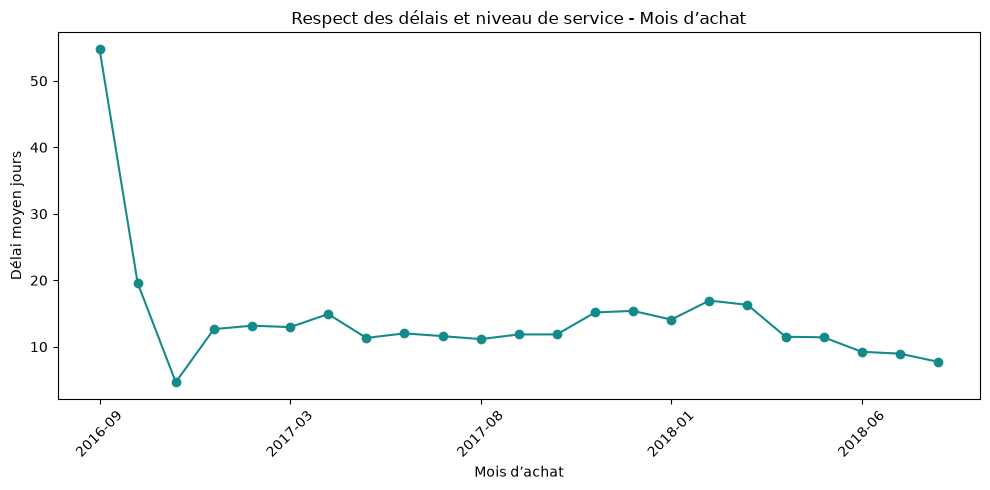

Visuel 2 - Respect des délais et niveau de service - Mois livraison


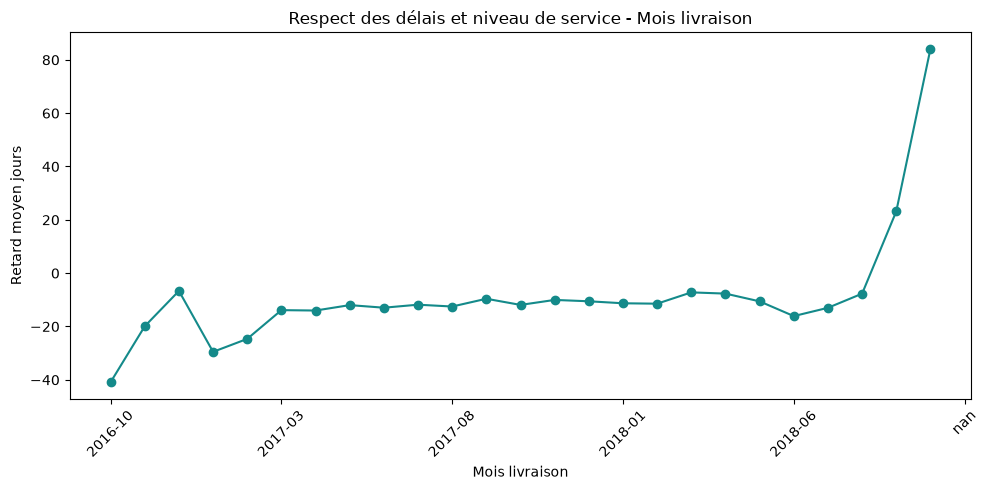

Visuel 3 - Respect des délais et niveau de service - Année achat


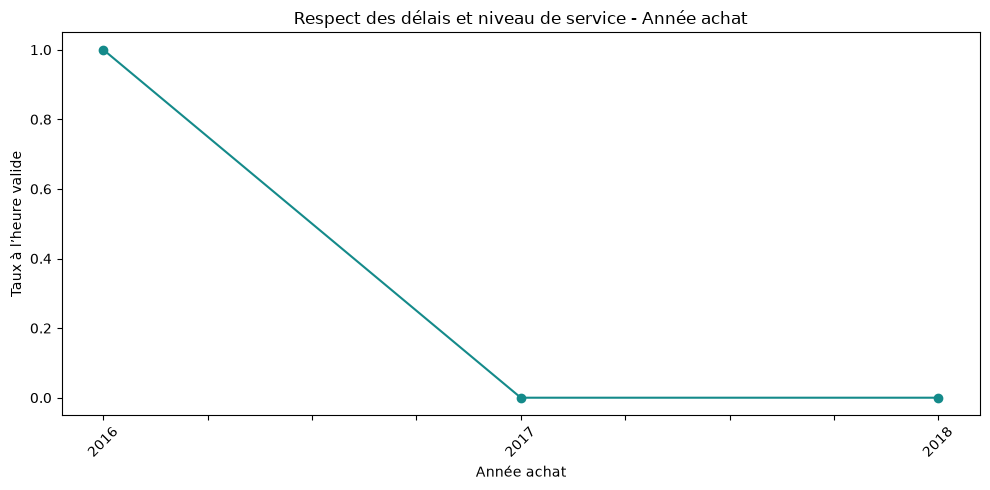

Visuel 4 - Respect des délais et niveau de service - État client


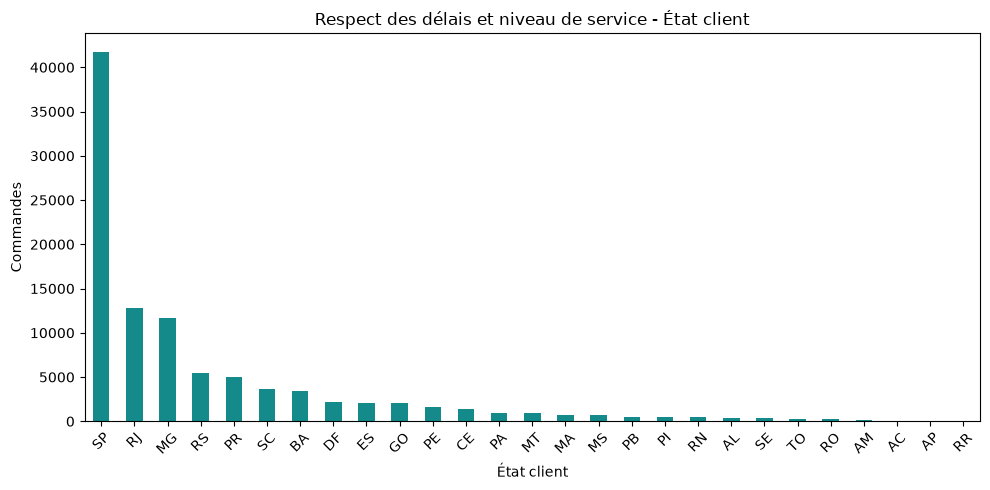

Visuel 5 - Respect des délais et niveau de service - Ville client


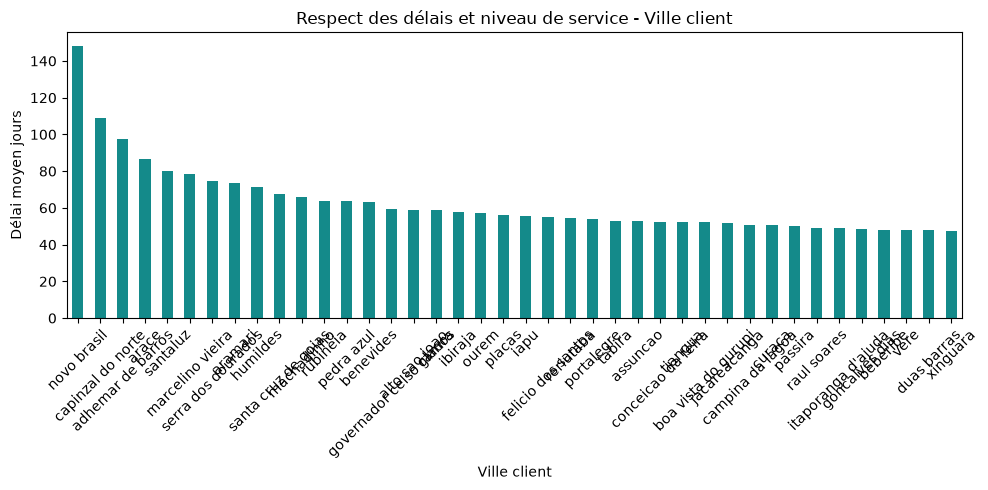

Visuel 6 - Respect des délais et niveau de service - Statut


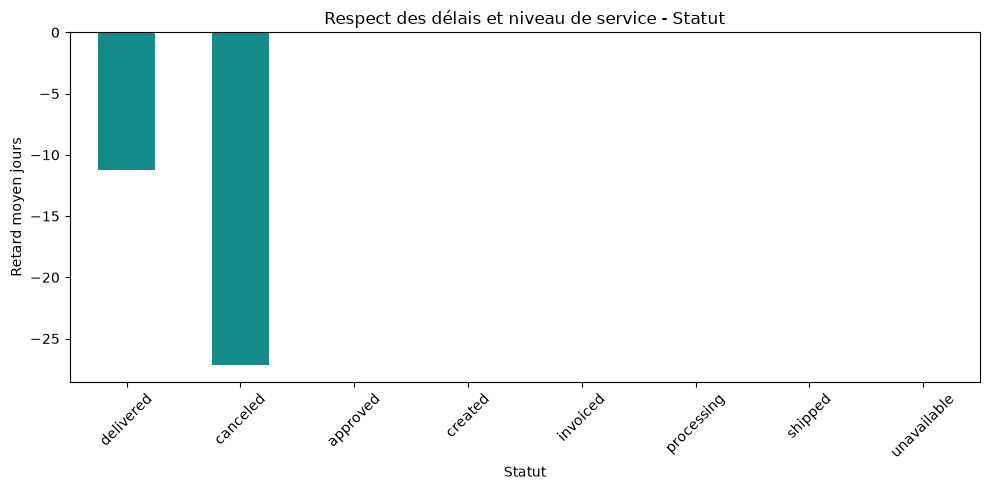

Visuel 7 - Respect des délais et niveau de service - Partie du jour achat


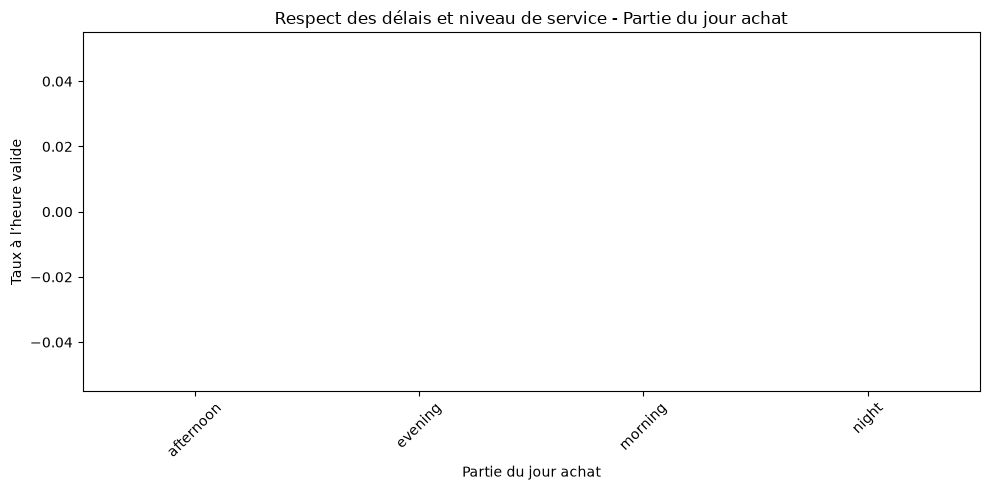

Visuel 8 - Respect des délais et niveau de service - Jour semaine achat


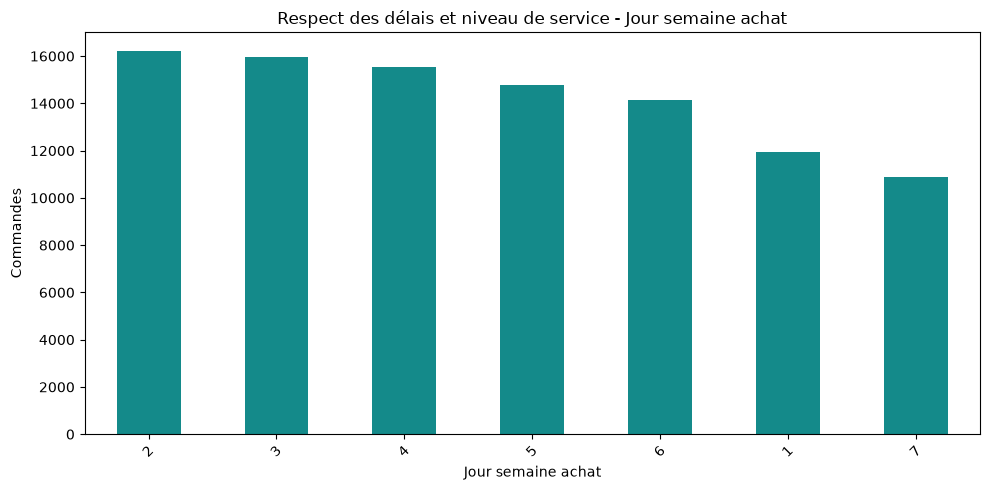

Visuel 9 - Respect des délais et niveau de service - Mois livraison x état


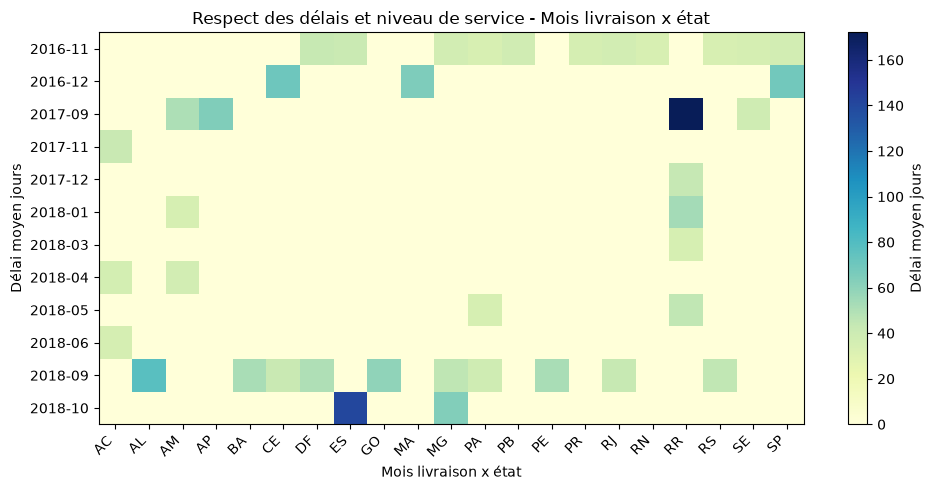

Visuel 10 - Respect des délais et niveau de service - Statut x mois achat


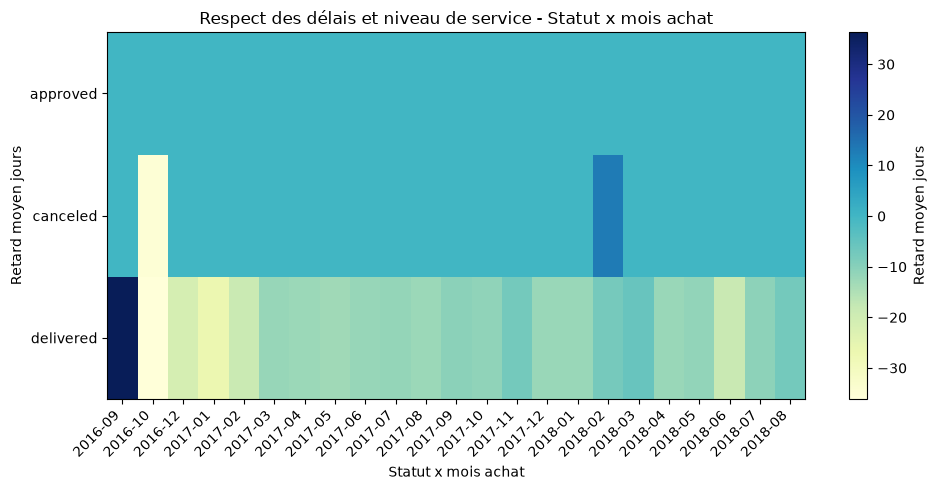

In [3]:
CHARTS=[
  {
    "n": 1,
    "title": "Respect des délais et niveau de service - Mois d’achat",
    "dim": {
      "label": "Mois d’achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "line"
  },
  {
    "n": 2,
    "title": "Respect des délais et niveau de service - Mois livraison",
    "dim": {
      "label": "Mois livraison",
      "sql": "SUBSTRING(\"delivered_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Respect des délais et niveau de service - Année achat",
    "dim": {
      "label": "Année achat",
      "sql": "\"purchase_date_year\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Taux à l’heure valide",
      "sql": "SUM(\"delivered_on_time\") / NULLIF(SUM(CASE WHEN \"status\" = 'delivered' AND \"delivered_date_calendar_date\" IS NOT NULL AND \"estimated_delivery_date_calendar_date\" IS NOT NULL THEN 1 ELSE 0 END),0)",
      "pandas": "delivered_on_time"
    },
    "kind": "line"
  },
  {
    "n": 4,
    "title": "Respect des délais et niveau de service - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Respect des délais et niveau de service - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Respect des délais et niveau de service - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Respect des délais et niveau de service - Partie du jour achat",
    "dim": {
      "label": "Partie du jour achat",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Taux à l’heure valide",
      "sql": "SUM(\"delivered_on_time\") / NULLIF(SUM(CASE WHEN \"status\" = 'delivered' AND \"delivered_date_calendar_date\" IS NOT NULL AND \"estimated_delivery_date_calendar_date\" IS NOT NULL THEN 1 ELSE 0 END),0)",
      "pandas": "delivered_on_time"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Respect des délais et niveau de service - Jour semaine achat",
    "dim": {
      "label": "Jour semaine achat",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "bar"
  },
  {
    "n": 9,
    "title": "Respect des délais et niveau de service - Mois livraison x état",
    "dim": {
      "label": "Mois livraison x état",
      "sql": "SUBSTRING(\"delivered_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Respect des délais et niveau de service - Statut x mois achat",
    "dim": {
      "label": "Statut x mois achat",
      "sql": "\"status\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 2. Géographie des retards et de la qualité de service

Comparer délai, retard et ponctualité selon la géographie client en gardant visibles les effectifs comparables.

**Drill-down :** État > ville > code postal; géographie client x vendeur représentatif; date de livraison > période.

Visuel 1 - Géographie des retards et de la qualité de service - État client


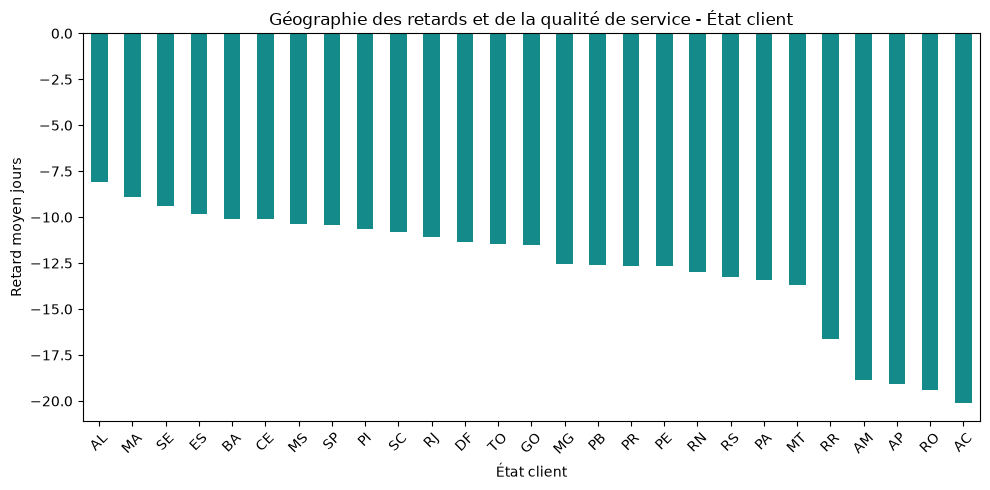

Visuel 2 - Géographie des retards et de la qualité de service - Ville client


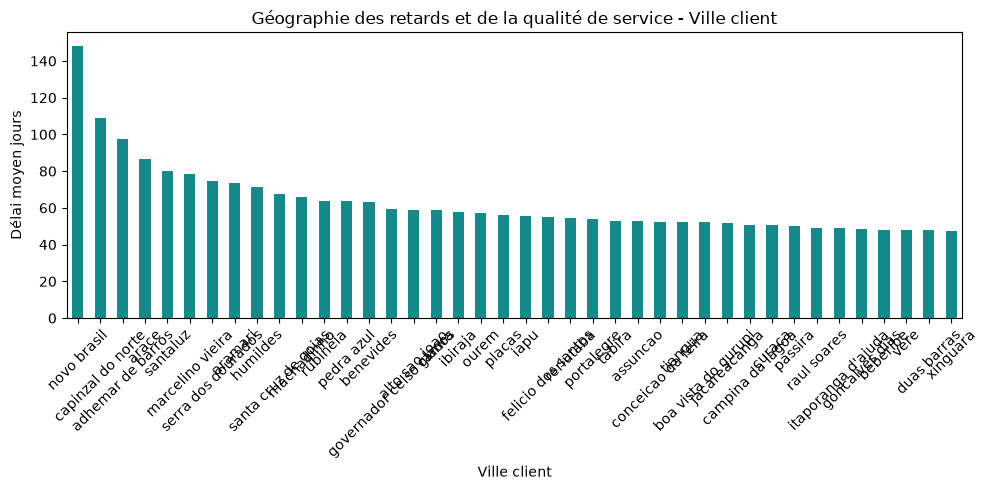

Visuel 3 - Géographie des retards et de la qualité de service - Code postal client


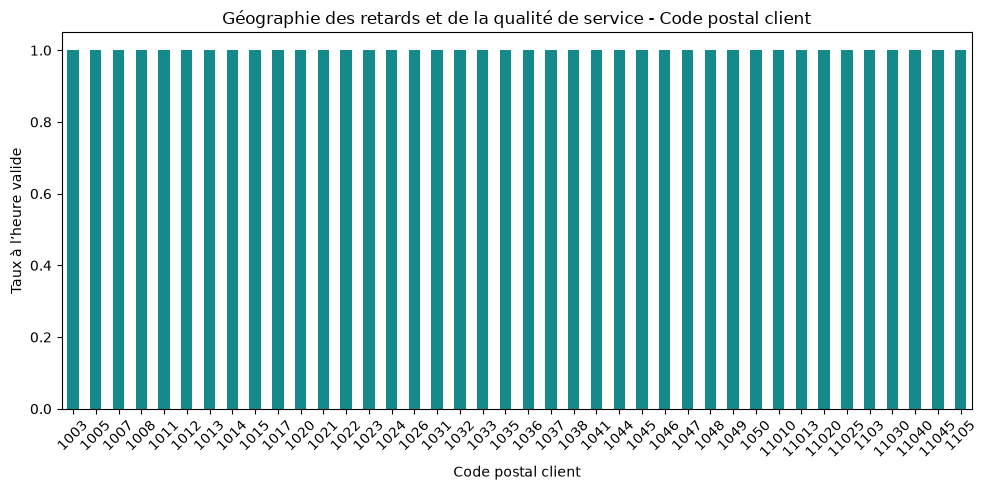

Visuel 4 - Géographie des retards et de la qualité de service - État vendeur représentatif


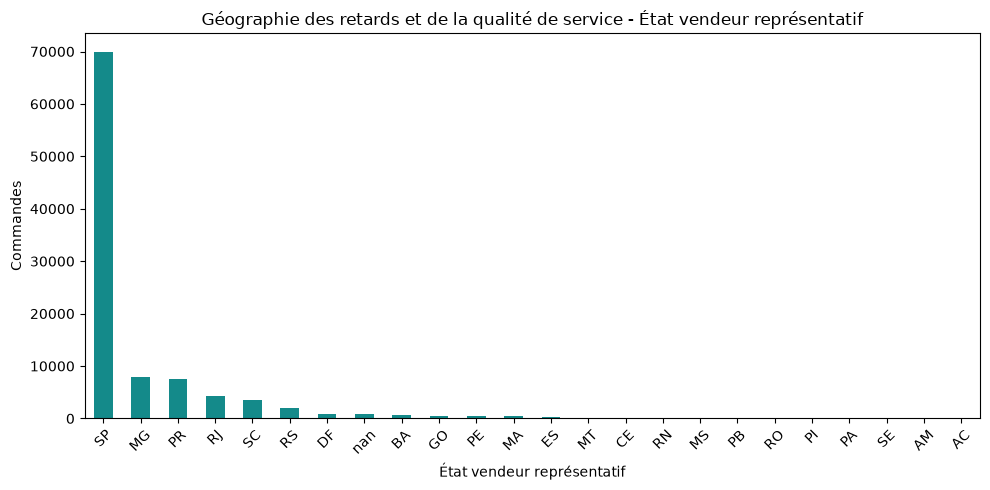

Visuel 5 - Géographie des retards et de la qualité de service - Ville vendeur représentatif


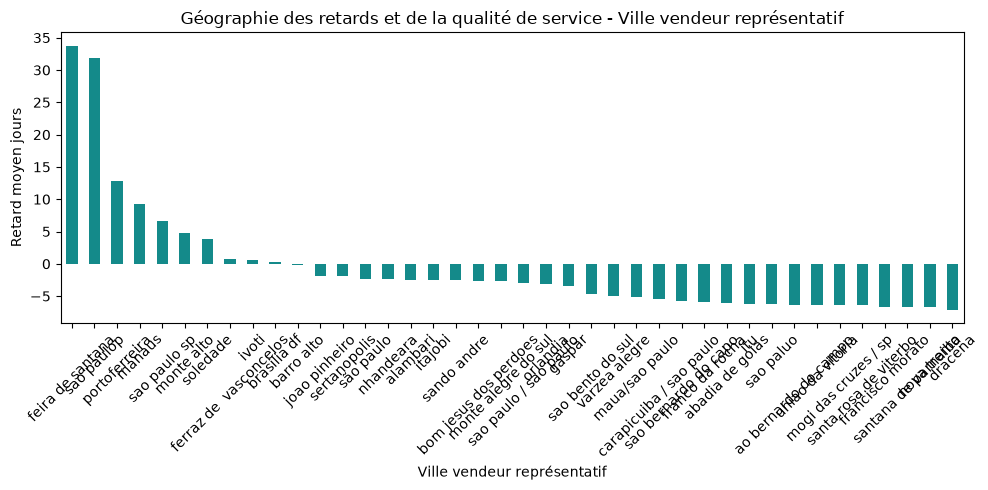

Visuel 6 - Géographie des retards et de la qualité de service - État client x état vendeur


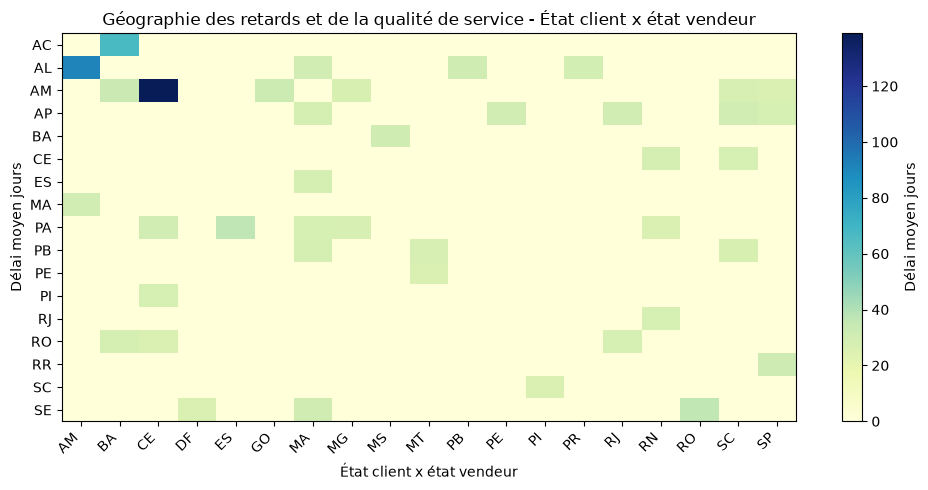

Visuel 7 - Géographie des retards et de la qualité de service - Ville client x statut


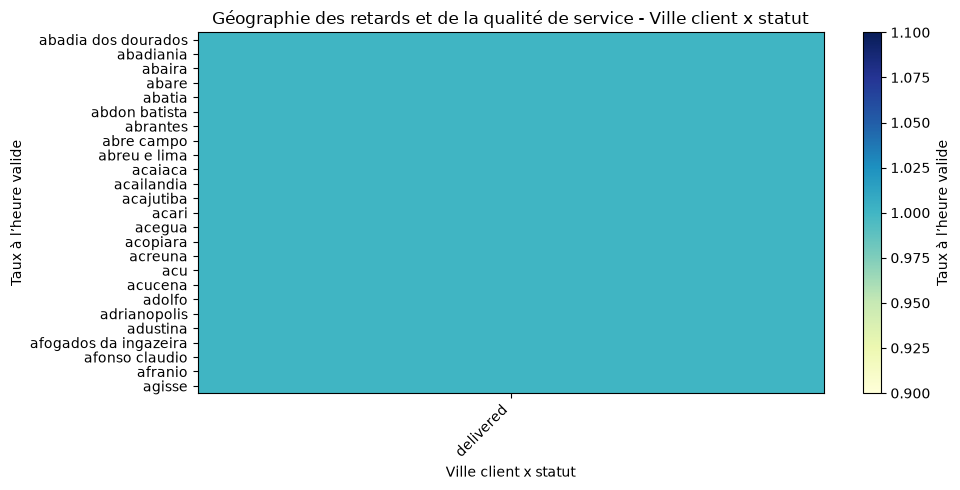

Visuel 8 - Géographie des retards et de la qualité de service - Mois livraison


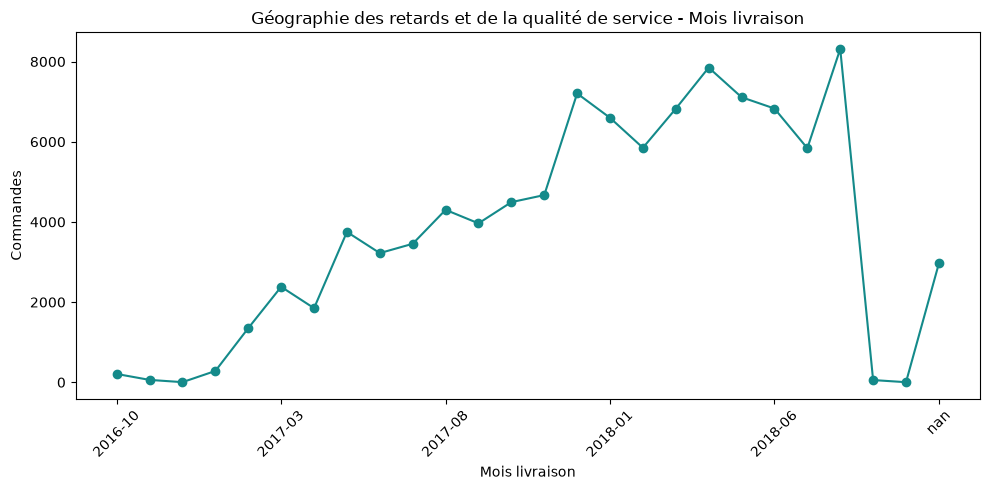

Visuel 9 - Géographie des retards et de la qualité de service - État x mois livraison


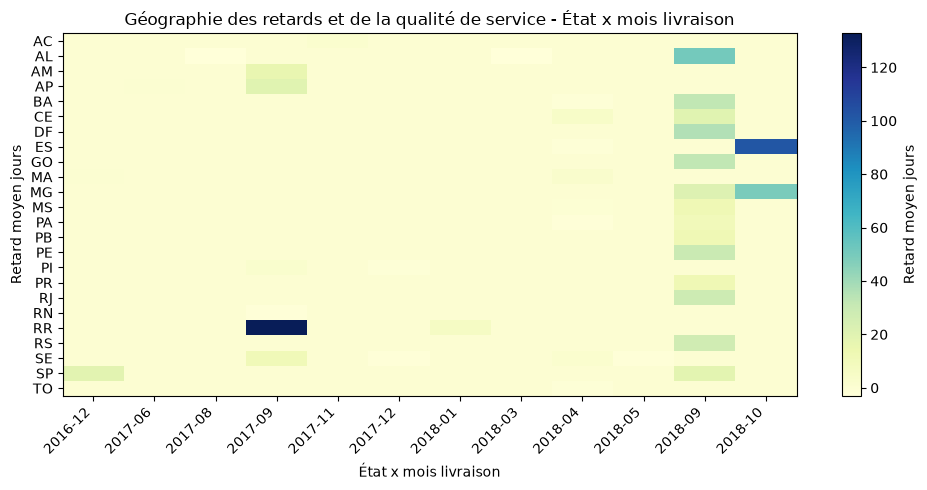

Visuel 10 - Géographie des retards et de la qualité de service - Vendeur représentatif


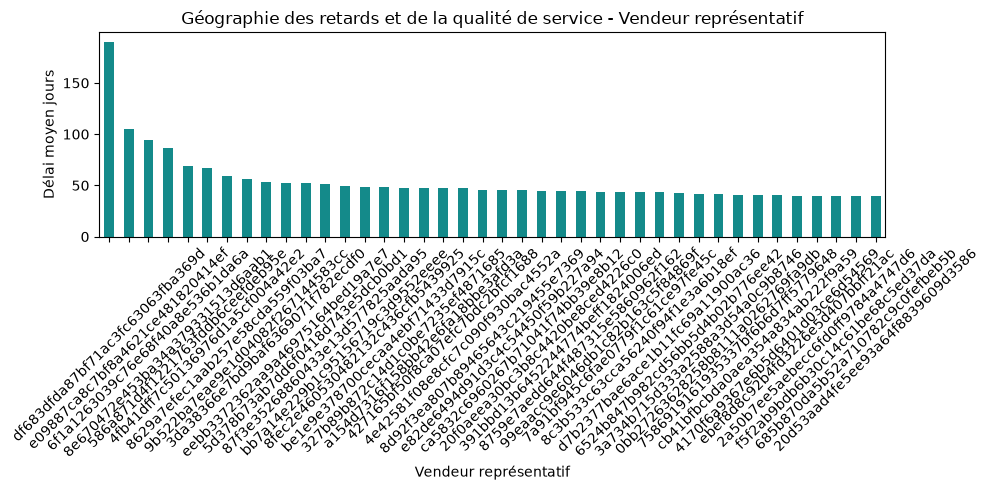

In [4]:
CHARTS=[
  {
    "n": 1,
    "title": "Géographie des retards et de la qualité de service - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Géographie des retards et de la qualité de service - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Géographie des retards et de la qualité de service - Code postal client",
    "dim": {
      "label": "Code postal client",
      "sql": "\"customer_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Taux à l’heure valide",
      "sql": "SUM(\"delivered_on_time\") / NULLIF(SUM(CASE WHEN \"status\" = 'delivered' AND \"delivered_date_calendar_date\" IS NOT NULL AND \"estimated_delivery_date_calendar_date\" IS NOT NULL THEN 1 ELSE 0 END),0)",
      "pandas": "delivered_on_time"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Géographie des retards et de la qualité de service - État vendeur représentatif",
    "dim": {
      "label": "État vendeur représentatif",
      "sql": "\"representative_seller_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Géographie des retards et de la qualité de service - Ville vendeur représentatif",
    "dim": {
      "label": "Ville vendeur représentatif",
      "sql": "\"representative_seller_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Géographie des retards et de la qualité de service - État client x état vendeur",
    "dim": {
      "label": "État client x état vendeur",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"representative_seller_state\""
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "heatmap"
  },
  {
    "n": 7,
    "title": "Géographie des retards et de la qualité de service - Ville client x statut",
    "dim": {
      "label": "Ville client x statut",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Taux à l’heure valide",
      "sql": "SUM(\"delivered_on_time\") / NULLIF(SUM(CASE WHEN \"status\" = 'delivered' AND \"delivered_date_calendar_date\" IS NOT NULL AND \"estimated_delivery_date_calendar_date\" IS NOT NULL THEN 1 ELSE 0 END),0)",
      "pandas": "delivered_on_time"
    },
    "kind": "heatmap"
  },
  {
    "n": 8,
    "title": "Géographie des retards et de la qualité de service - Mois livraison",
    "dim": {
      "label": "Mois livraison",
      "sql": "SUBSTRING(\"delivered_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "line"
  },
  {
    "n": 9,
    "title": "Géographie des retards et de la qualité de service - État x mois livraison",
    "dim": {
      "label": "État x mois livraison",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "SUBSTRING(\"delivered_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Géographie des retards et de la qualité de service - Vendeur représentatif",
    "dim": {
      "label": "Vendeur représentatif",
      "sql": "\"representative_seller_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 3. Performance des vendeurs et distance de desserte

Évaluer les délais et distances par vendeur représentatif, en explicitant la limite multi-vendeurs de la représentation.

**Drill-down :** État vendeur > ville > vendeur; vendeur x état client; distance > délais > ponctualité.

Visuel 1 - Performance des vendeurs et distance de desserte - Vendeur représentatif


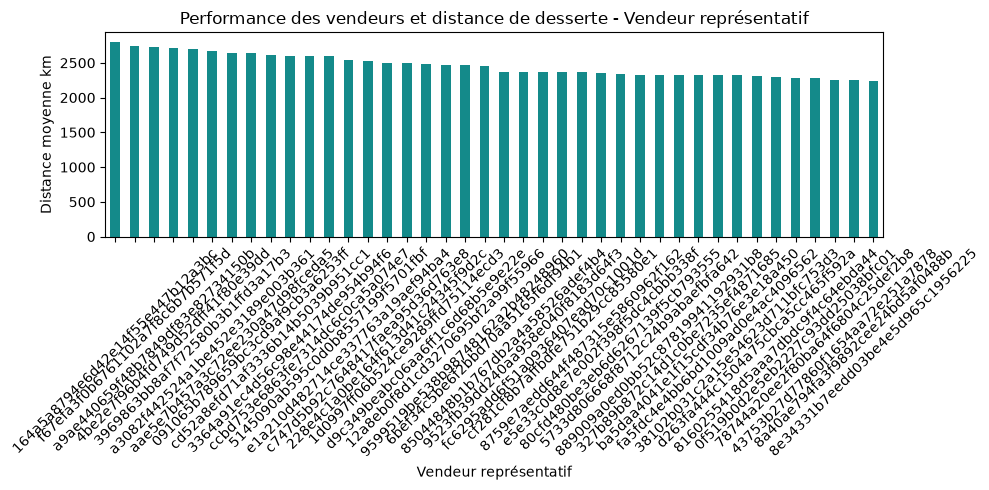

Visuel 2 - Performance des vendeurs et distance de desserte - État vendeur


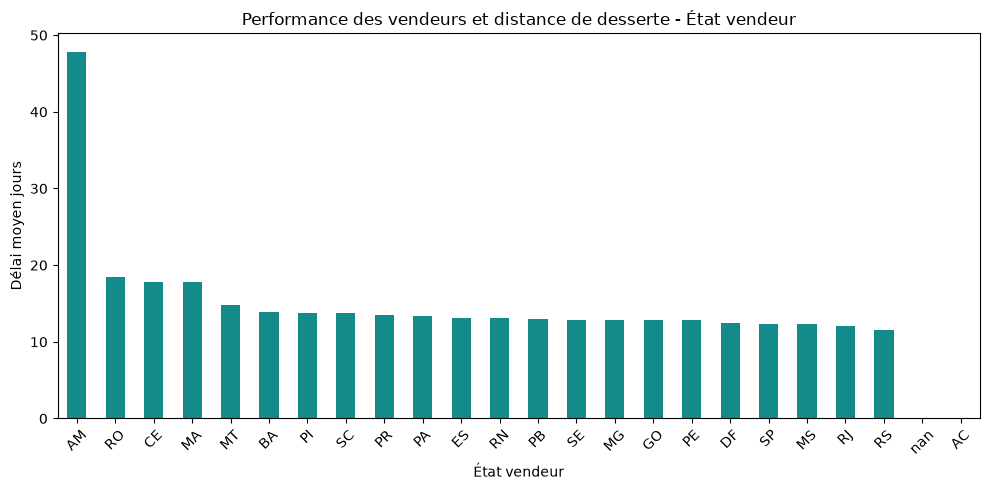

Visuel 3 - Performance des vendeurs et distance de desserte - Ville vendeur


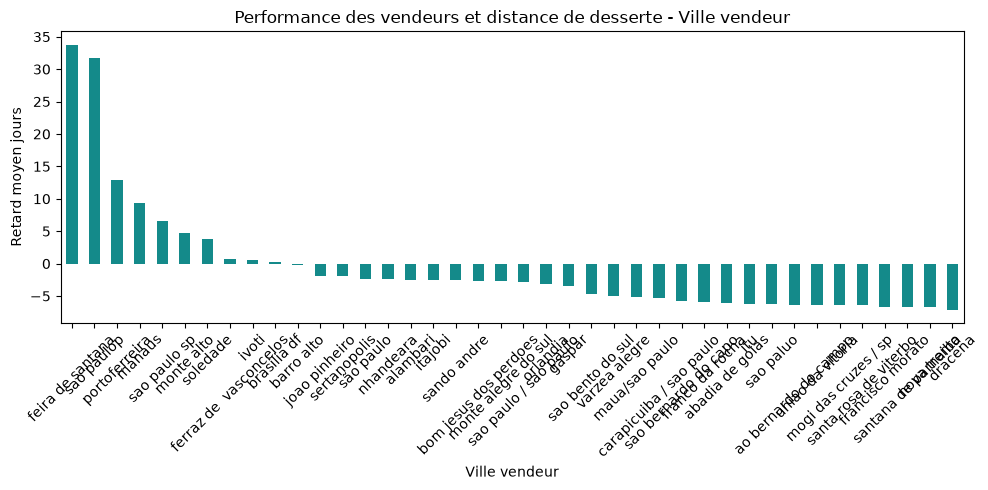

Visuel 4 - Performance des vendeurs et distance de desserte - État client


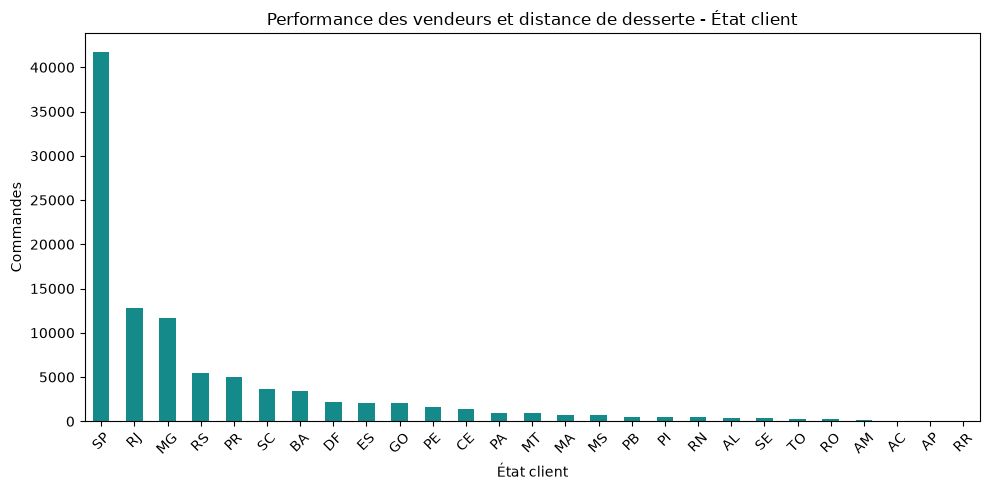

Visuel 5 - Performance des vendeurs et distance de desserte - Code postal vendeur


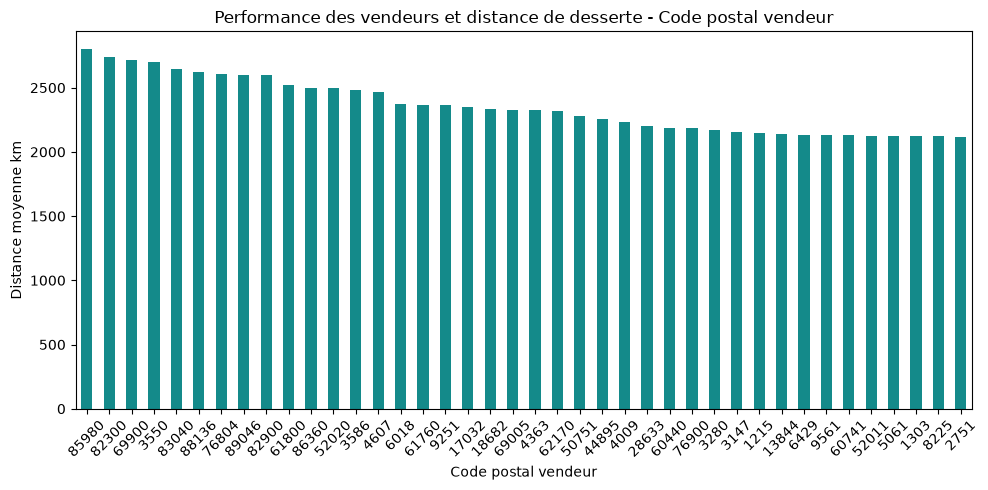

Visuel 6 - Performance des vendeurs et distance de desserte - Distance km par tranche


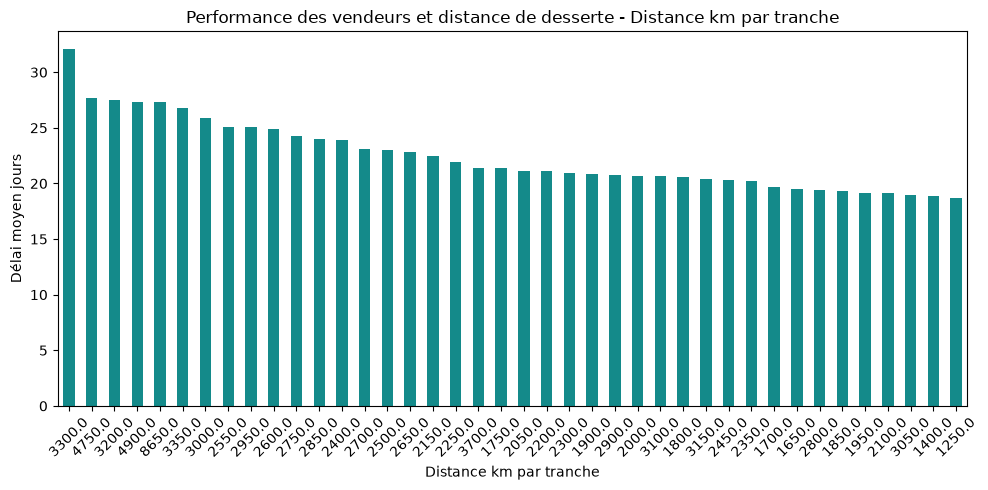

Visuel 7 - Performance des vendeurs et distance de desserte - Distance x retard


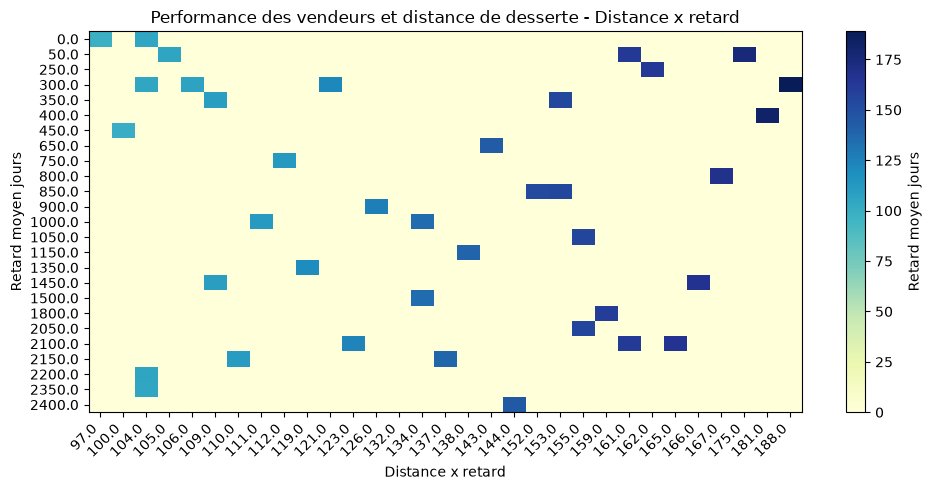

Visuel 8 - Performance des vendeurs et distance de desserte - Mois livraison


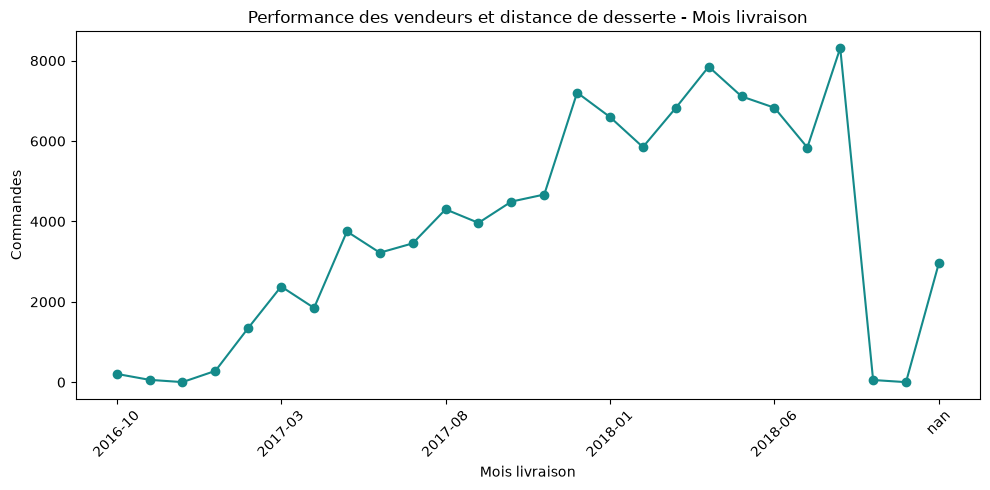

Visuel 9 - Performance des vendeurs et distance de desserte - Vendeur x état client


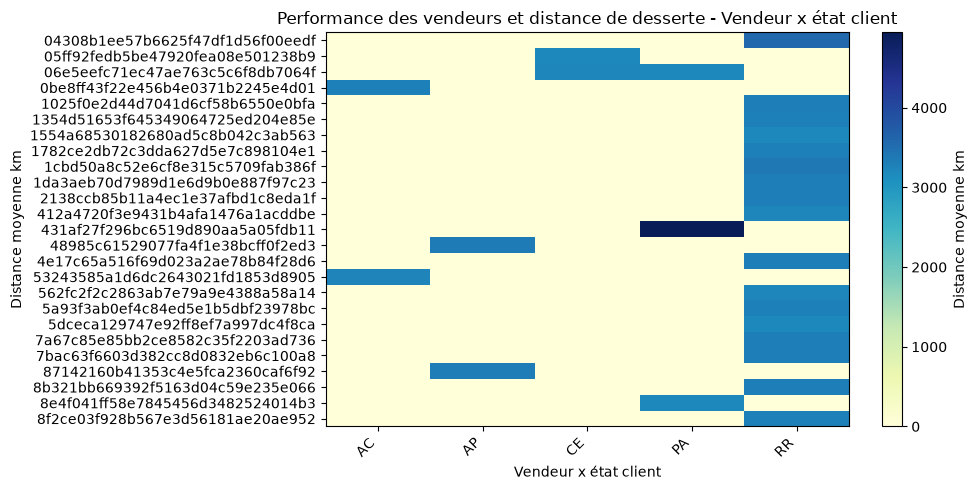

Visuel 10 - Performance des vendeurs et distance de desserte - Vendeur x statut


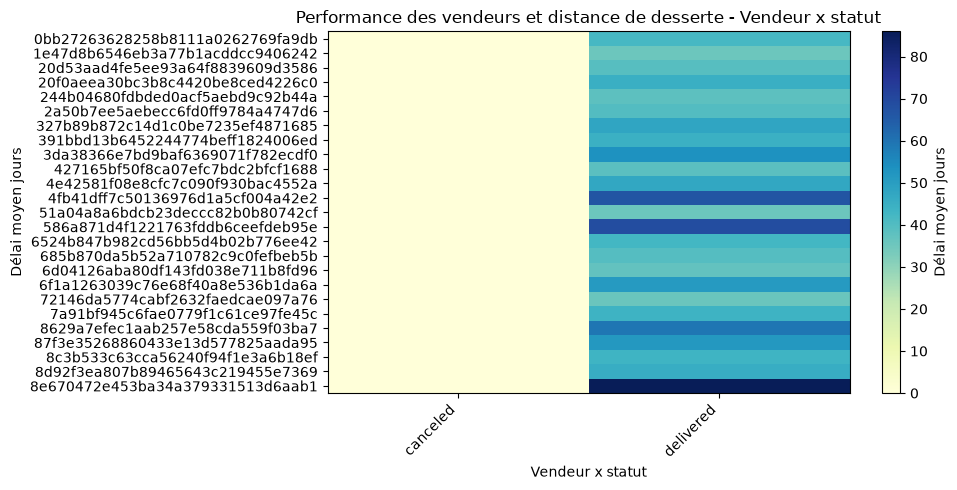

In [5]:
CHARTS=[
  {
    "n": 1,
    "title": "Performance des vendeurs et distance de desserte - Vendeur représentatif",
    "dim": {
      "label": "Vendeur représentatif",
      "sql": "\"representative_seller_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Distance moyenne km",
      "sql": "AVG(\"distance_km\")",
      "pandas": "distance_km"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Performance des vendeurs et distance de desserte - État vendeur",
    "dim": {
      "label": "État vendeur",
      "sql": "\"representative_seller_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Performance des vendeurs et distance de desserte - Ville vendeur",
    "dim": {
      "label": "Ville vendeur",
      "sql": "\"representative_seller_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Performance des vendeurs et distance de desserte - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Performance des vendeurs et distance de desserte - Code postal vendeur",
    "dim": {
      "label": "Code postal vendeur",
      "sql": "\"representative_seller_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Distance moyenne km",
      "sql": "AVG(\"distance_km\")",
      "pandas": "distance_km"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Performance des vendeurs et distance de desserte - Distance km par tranche",
    "dim": {
      "label": "Distance km par tranche",
      "sql": "FLOOR(\"distance_km\"/50)*50",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Performance des vendeurs et distance de desserte - Distance x retard",
    "dim": {
      "label": "Distance x retard",
      "sql": "FLOOR(\"distance_km\"/50)*50",
      "type": "numeric",
      "series": "FLOOR(\"late_days\")"
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "heatmap"
  },
  {
    "n": 8,
    "title": "Performance des vendeurs et distance de desserte - Mois livraison",
    "dim": {
      "label": "Mois livraison",
      "sql": "SUBSTRING(\"delivered_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "line"
  },
  {
    "n": 9,
    "title": "Performance des vendeurs et distance de desserte - Vendeur x état client",
    "dim": {
      "label": "Vendeur x état client",
      "sql": "\"representative_seller_id\"",
      "type": "categorical",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Distance moyenne km",
      "sql": "AVG(\"distance_km\")",
      "pandas": "distance_km"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Performance des vendeurs et distance de desserte - Vendeur x statut",
    "dim": {
      "label": "Vendeur x statut",
      "sql": "\"representative_seller_id\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 4. Analyse des jalons du cycle logistique

Suivre le volume des commandes par dates d’achat, expédition, livraison et estimation pour localiser les périodes à investiguer.

**Drill-down :** Achat > expédition > livraison; date estimée comparée à la date de livraison; heure > partie du jour.

Visuel 1 - Analyse des jalons du cycle logistique - Mois achat


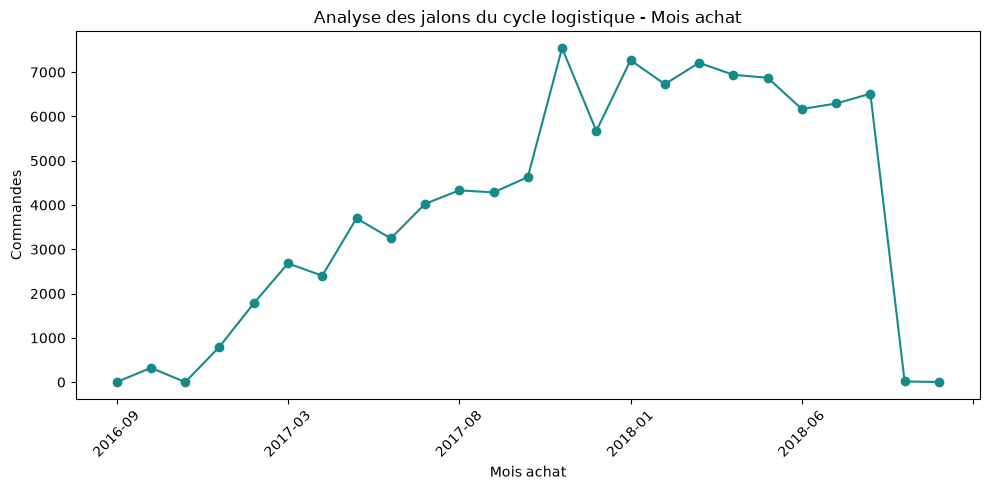

Visuel 2 - Analyse des jalons du cycle logistique - Mois expédition


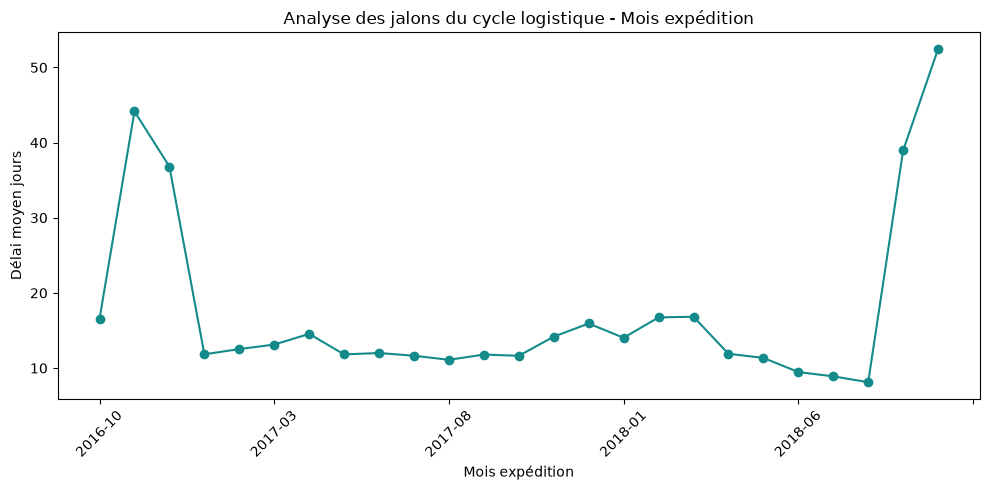

Visuel 3 - Analyse des jalons du cycle logistique - Mois livraison


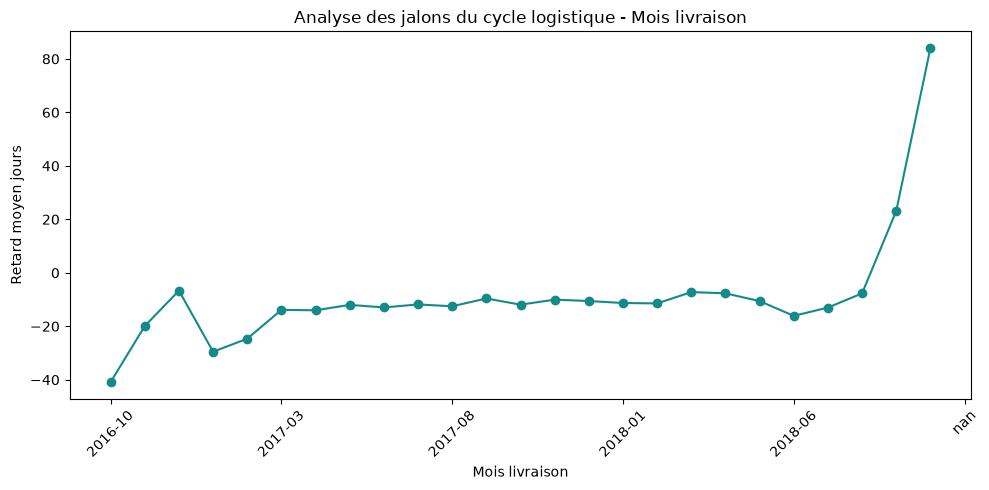

Visuel 4 - Analyse des jalons du cycle logistique - Mois estimation


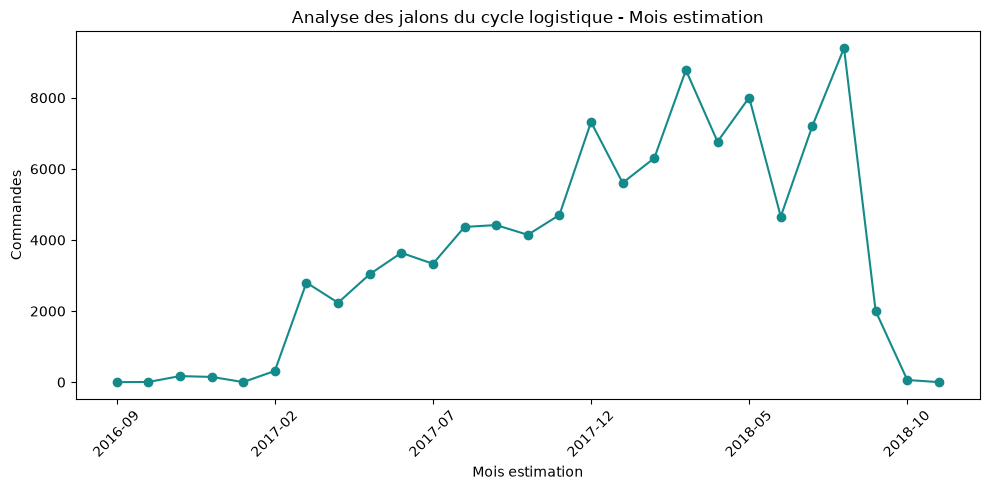

Visuel 5 - Analyse des jalons du cycle logistique - Année expédition


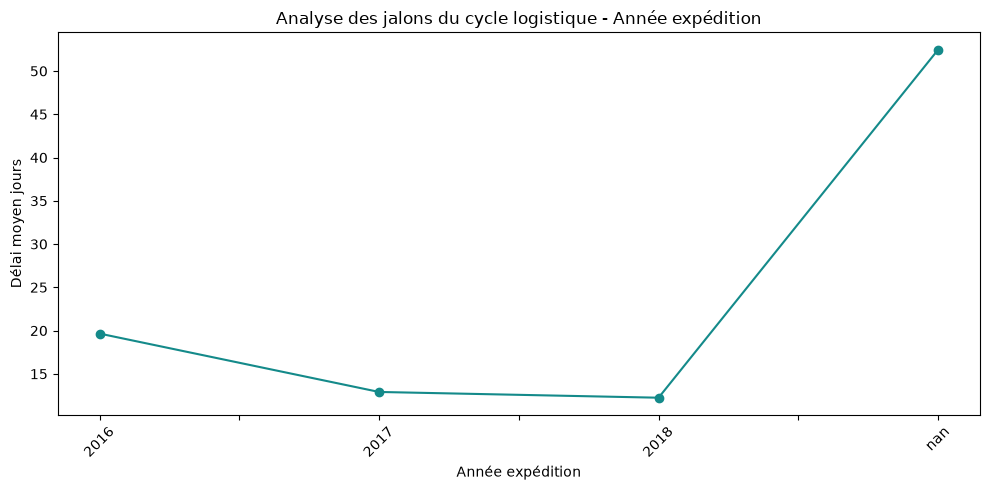

Visuel 6 - Analyse des jalons du cycle logistique - Statut


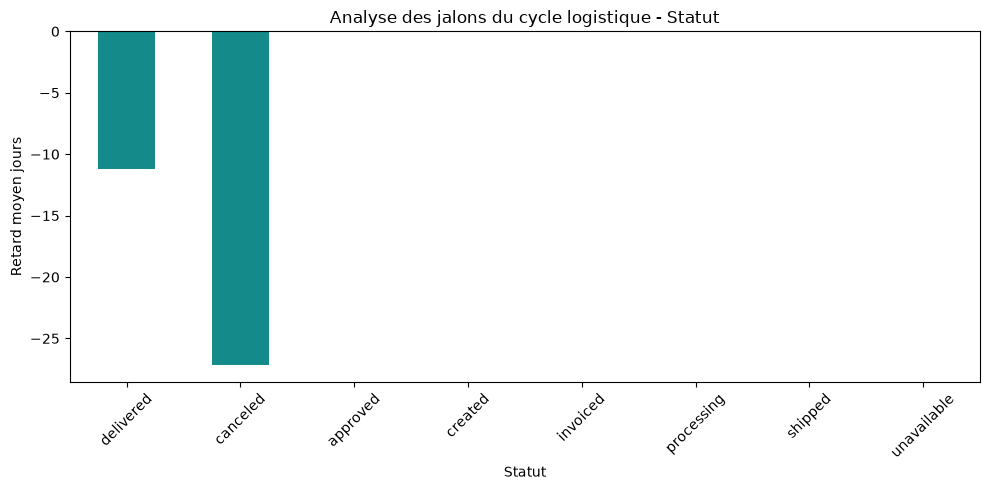

Visuel 7 - Analyse des jalons du cycle logistique - Partie du jour achat


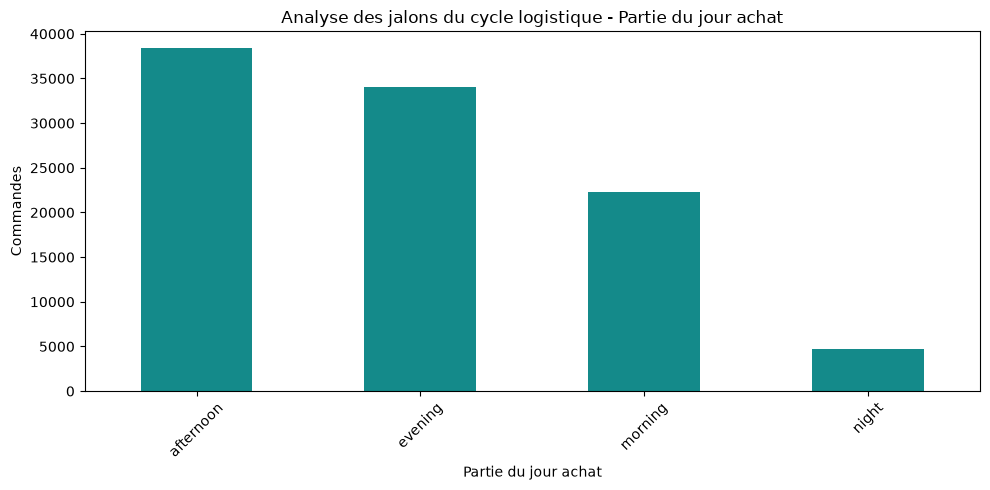

Visuel 8 - Analyse des jalons du cycle logistique - Heure livraison


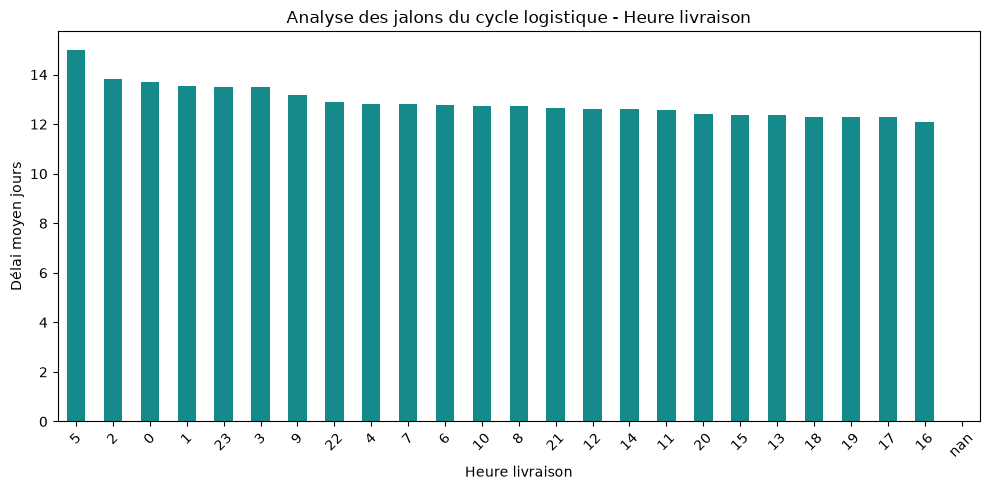

Visuel 9 - Analyse des jalons du cycle logistique - Statut x mois livraison


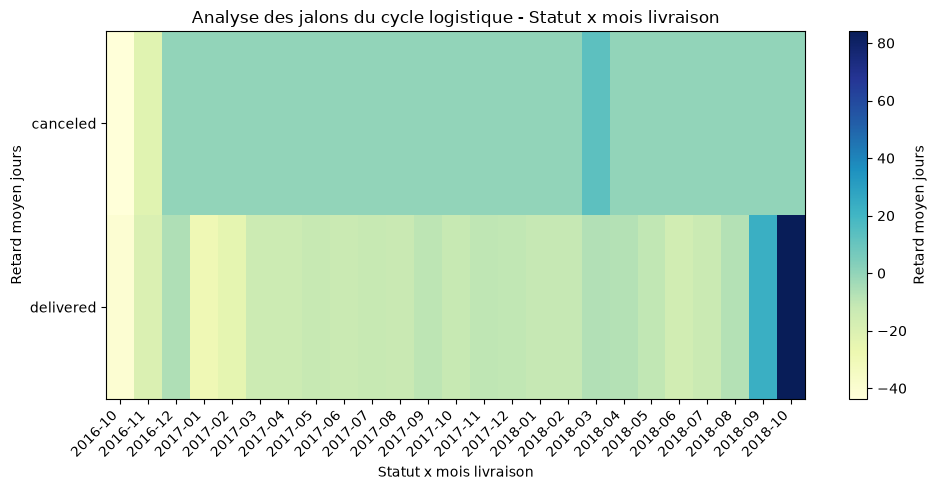

Visuel 10 - Analyse des jalons du cycle logistique - État x mois livraison


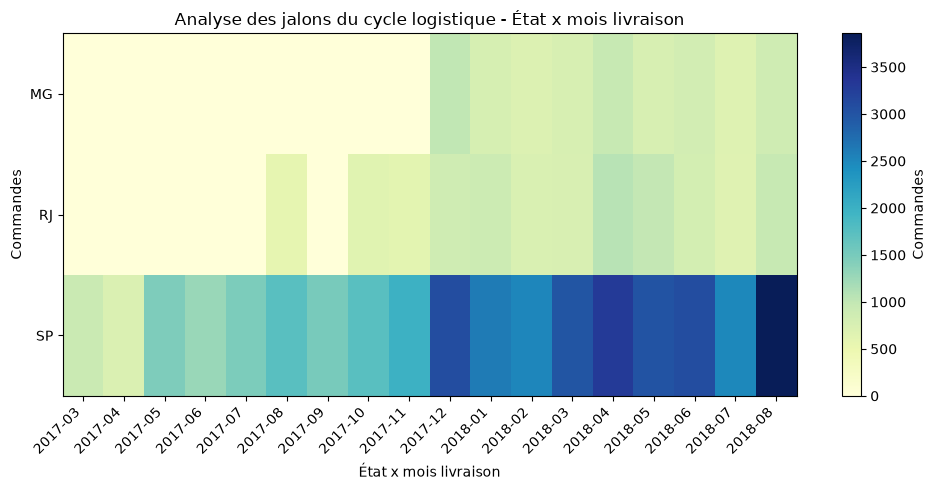

In [6]:
CHARTS=[
  {
    "n": 1,
    "title": "Analyse des jalons du cycle logistique - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "line"
  },
  {
    "n": 2,
    "title": "Analyse des jalons du cycle logistique - Mois expédition",
    "dim": {
      "label": "Mois expédition",
      "sql": "SUBSTRING(\"shipped_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Analyse des jalons du cycle logistique - Mois livraison",
    "dim": {
      "label": "Mois livraison",
      "sql": "SUBSTRING(\"delivered_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "line"
  },
  {
    "n": 4,
    "title": "Analyse des jalons du cycle logistique - Mois estimation",
    "dim": {
      "label": "Mois estimation",
      "sql": "SUBSTRING(\"estimated_delivery_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "line"
  },
  {
    "n": 5,
    "title": "Analyse des jalons du cycle logistique - Année expédition",
    "dim": {
      "label": "Année expédition",
      "sql": "\"shipped_date_year\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "line"
  },
  {
    "n": 6,
    "title": "Analyse des jalons du cycle logistique - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Analyse des jalons du cycle logistique - Partie du jour achat",
    "dim": {
      "label": "Partie du jour achat",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Analyse des jalons du cycle logistique - Heure livraison",
    "dim": {
      "label": "Heure livraison",
      "sql": "\"delivered_time_hour\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "bar"
  },
  {
    "n": 9,
    "title": "Analyse des jalons du cycle logistique - Statut x mois livraison",
    "dim": {
      "label": "Statut x mois livraison",
      "sql": "\"status\"",
      "type": "categorical",
      "series": "SUBSTRING(\"delivered_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Analyse des jalons du cycle logistique - État x mois livraison",
    "dim": {
      "label": "État x mois livraison",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "SUBSTRING(\"delivered_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 5. Distance, délai et profils opérationnels

Explorer la relation entre distance, délai, retard, statut et période sans conclure à une causalité.

**Drill-down :** Distance > état client / vendeur > délai; période et statut comme contexte; drill-through commande.

Visuel 1 - Distance, délai et profils opérationnels - Distance tranche 25 km


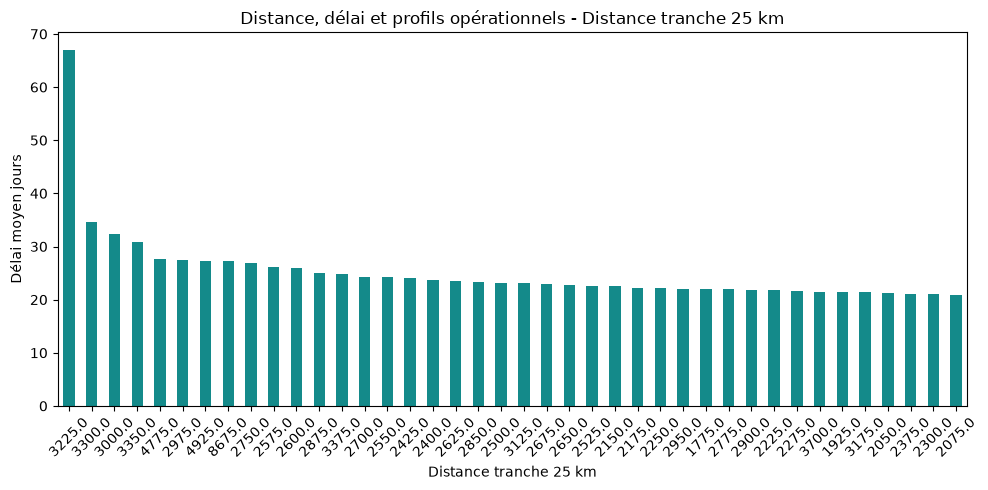

Visuel 2 - Distance, délai et profils opérationnels - Délai tranche 2 jours


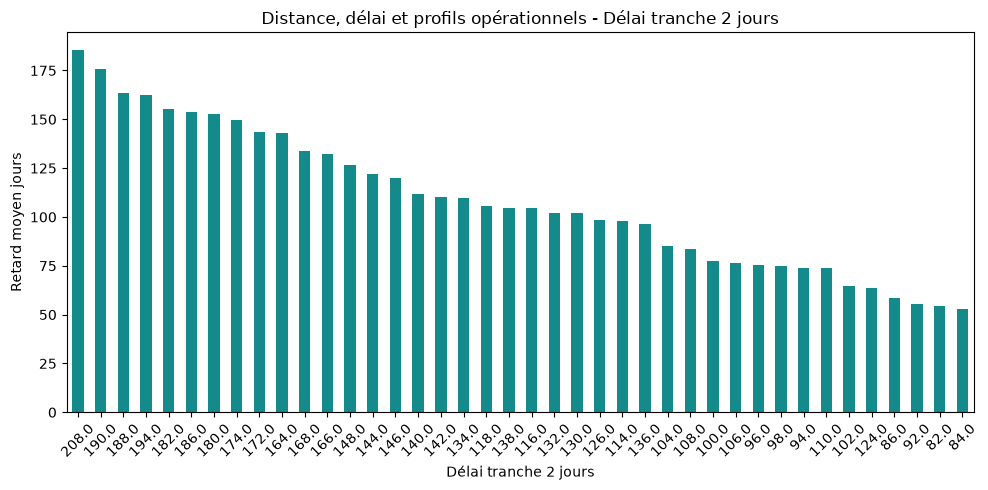

Visuel 3 - Distance, délai et profils opérationnels - Retard tranche 2 jours


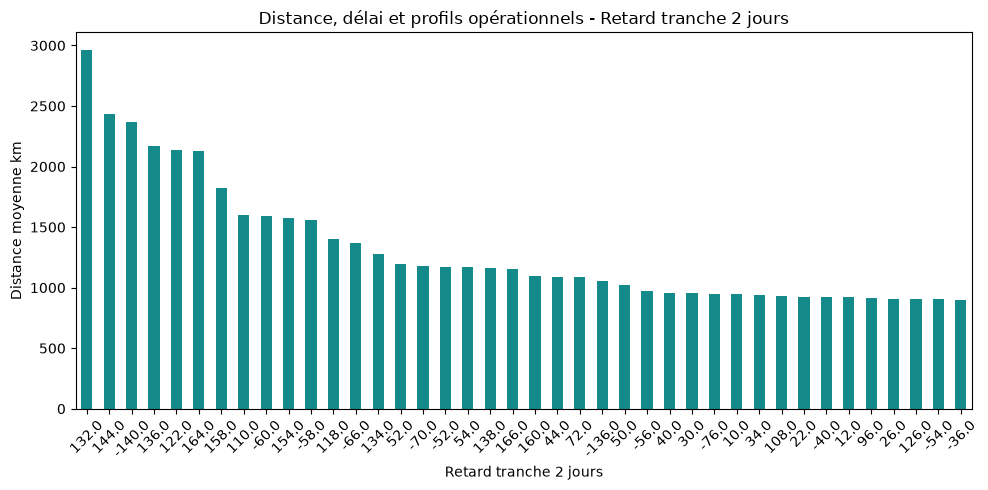

Visuel 4 - Distance, délai et profils opérationnels - État client


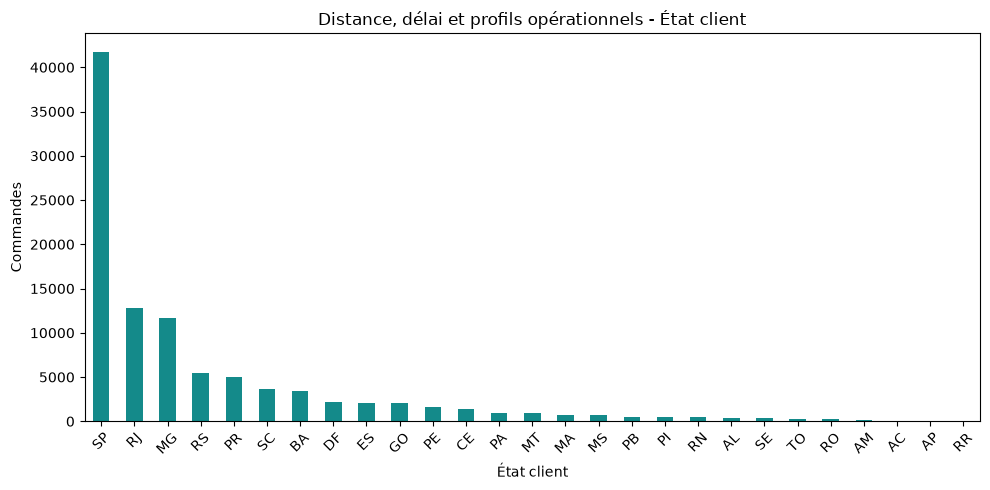

Visuel 5 - Distance, délai et profils opérationnels - État vendeur


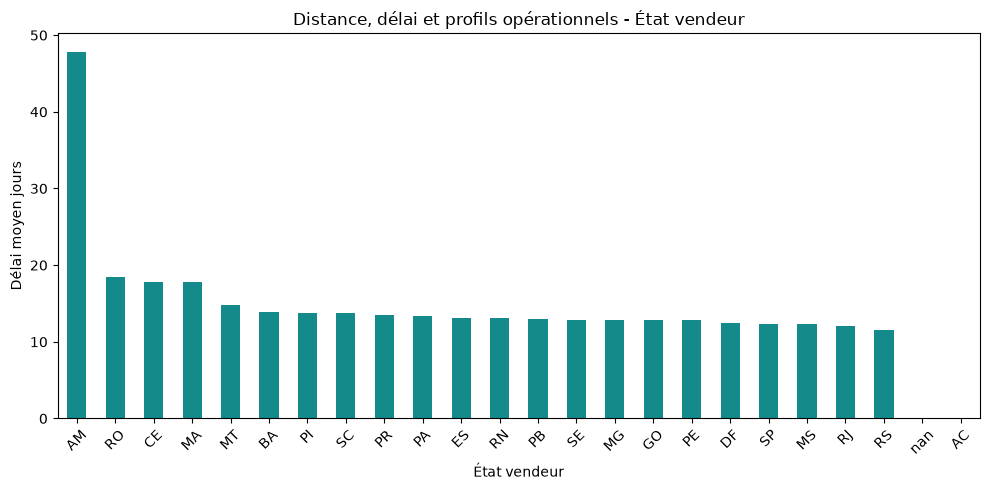

Visuel 6 - Distance, délai et profils opérationnels - Mois achat


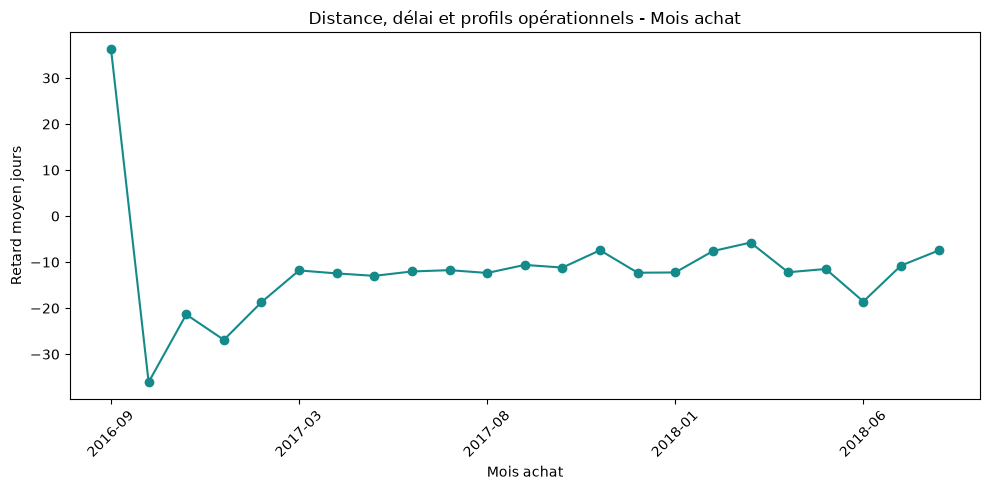

Visuel 7 - Distance, délai et profils opérationnels - Statut


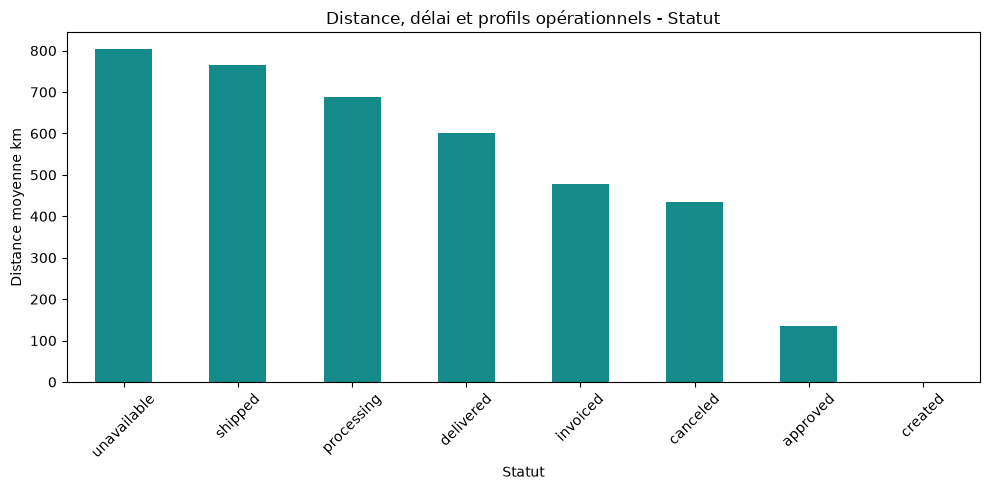

Visuel 8 - Distance, délai et profils opérationnels - Distance x délai


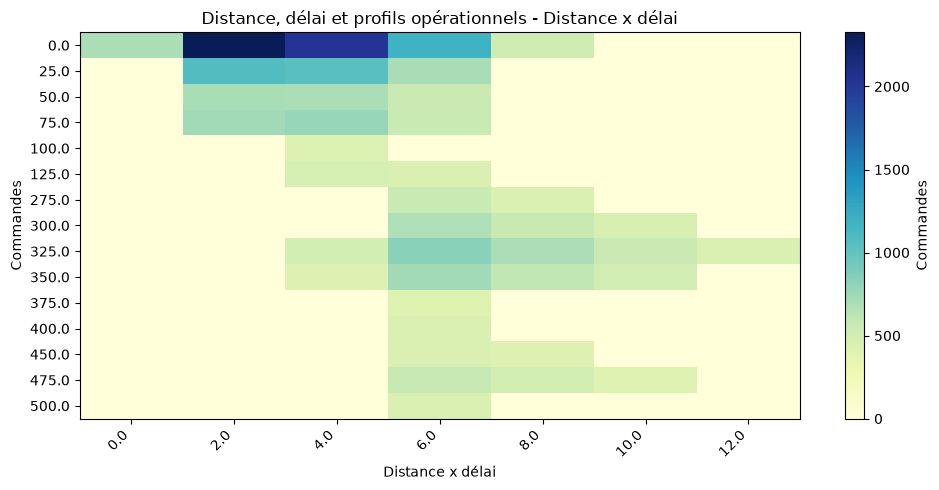

Visuel 9 - Distance, délai et profils opérationnels - État x statut


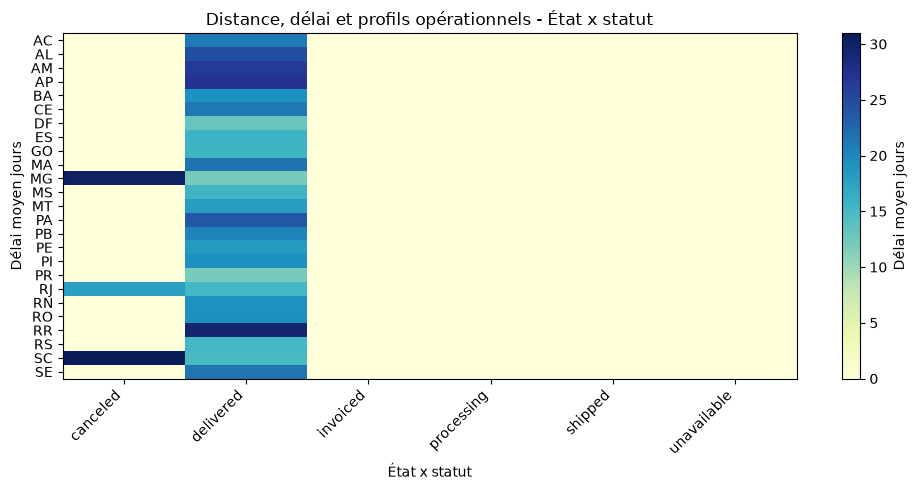

Visuel 10 - Distance, délai et profils opérationnels - Mois x statut


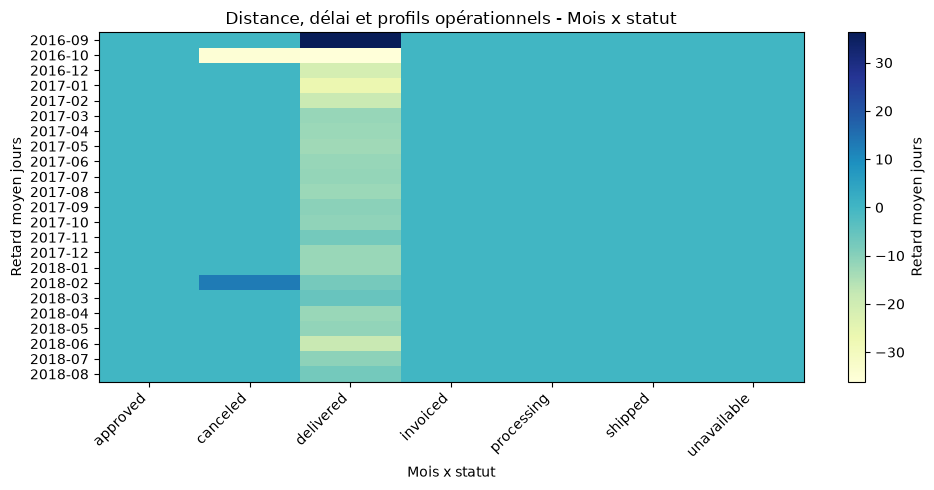

In [7]:
CHARTS=[
  {
    "n": 1,
    "title": "Distance, délai et profils opérationnels - Distance tranche 25 km",
    "dim": {
      "label": "Distance tranche 25 km",
      "sql": "FLOOR(\"distance_km\"/25)*25",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Distance, délai et profils opérationnels - Délai tranche 2 jours",
    "dim": {
      "label": "Délai tranche 2 jours",
      "sql": "FLOOR(\"delivery_days\"/2)*2",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Distance, délai et profils opérationnels - Retard tranche 2 jours",
    "dim": {
      "label": "Retard tranche 2 jours",
      "sql": "FLOOR(\"late_days\"/2)*2",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Distance moyenne km",
      "sql": "AVG(\"distance_km\")",
      "pandas": "distance_km"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Distance, délai et profils opérationnels - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Distance, délai et profils opérationnels - État vendeur",
    "dim": {
      "label": "État vendeur",
      "sql": "\"representative_seller_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Distance, délai et profils opérationnels - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "line"
  },
  {
    "n": 7,
    "title": "Distance, délai et profils opérationnels - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Distance moyenne km",
      "sql": "AVG(\"distance_km\")",
      "pandas": "distance_km"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Distance, délai et profils opérationnels - Distance x délai",
    "dim": {
      "label": "Distance x délai",
      "sql": "FLOOR(\"distance_km\"/25)*25",
      "type": "numeric",
      "series": "FLOOR(\"delivery_days\"/2)*2"
    },
    "metric": {
      "label": "Commandes",
      "sql": "SUM(\"orders_count\")",
      "pandas": "orders_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Distance, délai et profils opérationnels - État x statut",
    "dim": {
      "label": "État x statut",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Délai moyen jours",
      "sql": "AVG(\"delivery_days\")",
      "pandas": "delivery_days"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Distance, délai et profils opérationnels - Mois x statut",
    "dim": {
      "label": "Mois x statut",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": "\"status\""
    },
    "metric": {
      "label": "Retard moyen jours",
      "sql": "AVG(\"late_days\")",
      "pandas": "late_days"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## Lecture des résultats\n\nComparer les valeurs aux volumes, vérifier les petits effectifs et suivre les chemins de drill-down du dossier. Les ratios et moyennes se recalculent au niveau affiché. Une association ne démontre pas une causalité.